# 02 — EDA, model evaluation and decision planning



In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/broadway").exists(), "Start in the project root or notebooks directory"
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown, Code
from broadway.config import (AUDIT, FEATURES, FIGURES, MODELS, TABLES, RAW,
                             PREDICTORS, NUMERIC, GRID, FOLDS)
from broadway.io import read_json, sha256
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)


In [2]:
REBUILD_DEVELOPMENT = False
if REBUILD_DEVELOPMENT:
    if (TABLES / "final_evaluation_receipt.json").exists():
        raise RuntimeError("Final evaluation exists; do not retune after viewing it.")
    from broadway.eda import generate_eda
    from broadway.modelling import run_validation
    generate_eda()
    run_validation()
    print("Rebuilt development EDA, tuning and pre-2018 model fits.")
else:
    print("Review mode: preserved development evidence; no model fitting.")
frozen = read_json(MODELS / "frozen_protocol.json")
figure_index = pd.read_csv(TABLES / "figure_index.csv")
display(read_json(TABLES / "eda_scope.json"))

Review mode: preserved development evidence; no model fitting.


{'max_target_date': '2014-12-28',
 'cleaned_rows': 39067,
 'eligible_rows': 34565,
 'figures': 6,
 'coverage_note': 'Run lengths are observed within the truncated exploratory period, not official lifetime lengths.',
 'source_parquet': 'D:\\3rd Year\\DS\\data\\processed\\broadway_features.parquet',
 'final_holdout_used': False}

## Task 3 - Scope and reading the figures

[TidyTuesday / Alex Cookson / Playbill](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-04-28).


### Figure 1 — Weekly trend

A median per reported show is not total market revenue. Compare levels and variability alongside reporting counts. Discuss nominal-price and composition effects.

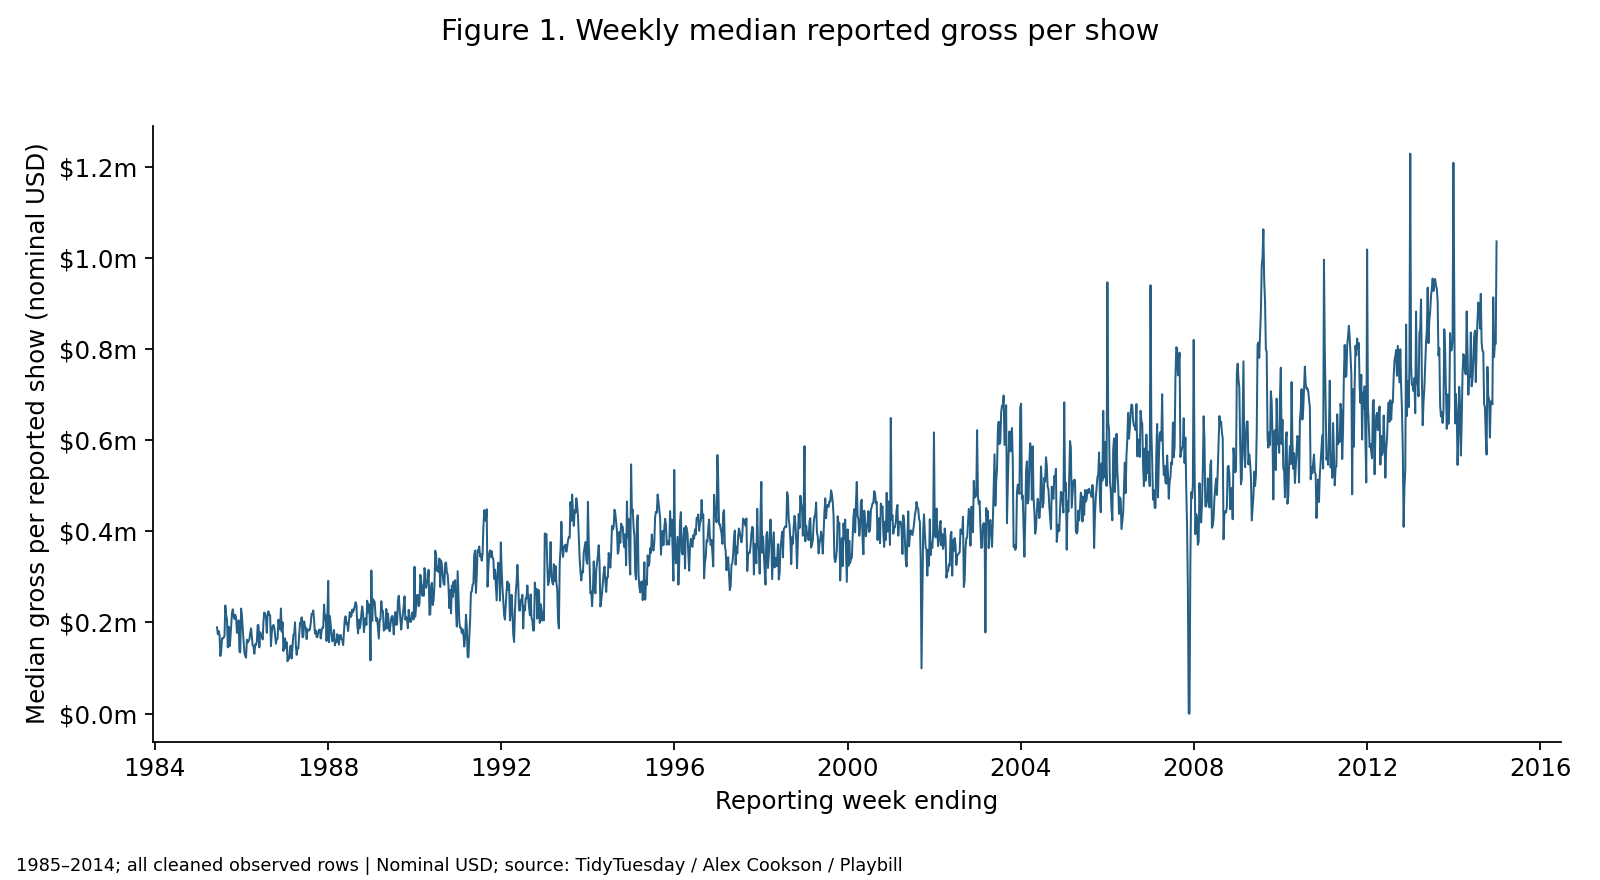

Scope: 1985–2014; all cleaned observed rows


In [3]:
figure = figure_index.loc[figure_index.figure == 1].iloc[0]
display(Image(filename=str(FIGURES / figure.file)))
print("Scope:", figure.scope)

### Figure 2 — Distribution

Counts represent show–theatre–weeks, not unique shows. Inspect concentration, tails and zero values; investigate particular cases using the anomaly examples.


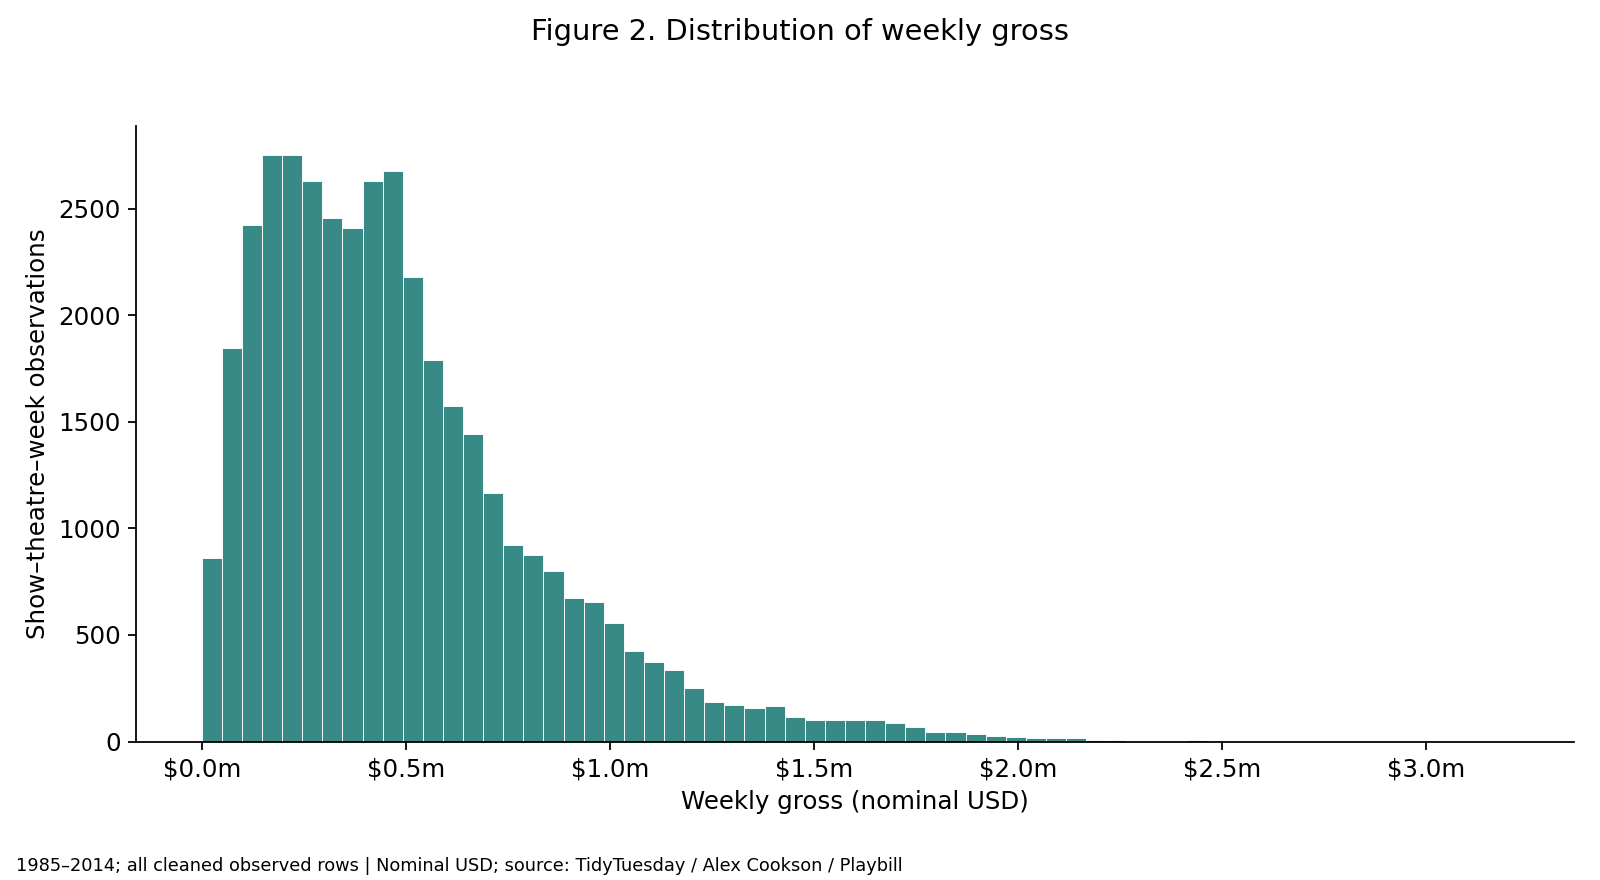

Scope: 1985–2014; all cleaned observed rows


In [4]:
figure = figure_index.loc[figure_index.figure == 2].iloc[0]
display(Image(filename=str(FIGURES / figure.file)))
print("Scope:", figure.scope)

### Figure 3 — Month patterns

Boxes show quartiles and medians within 2010–2014. Points outside whiskers are not automatically errors. Discuss seasonality and composition without assuming causation.

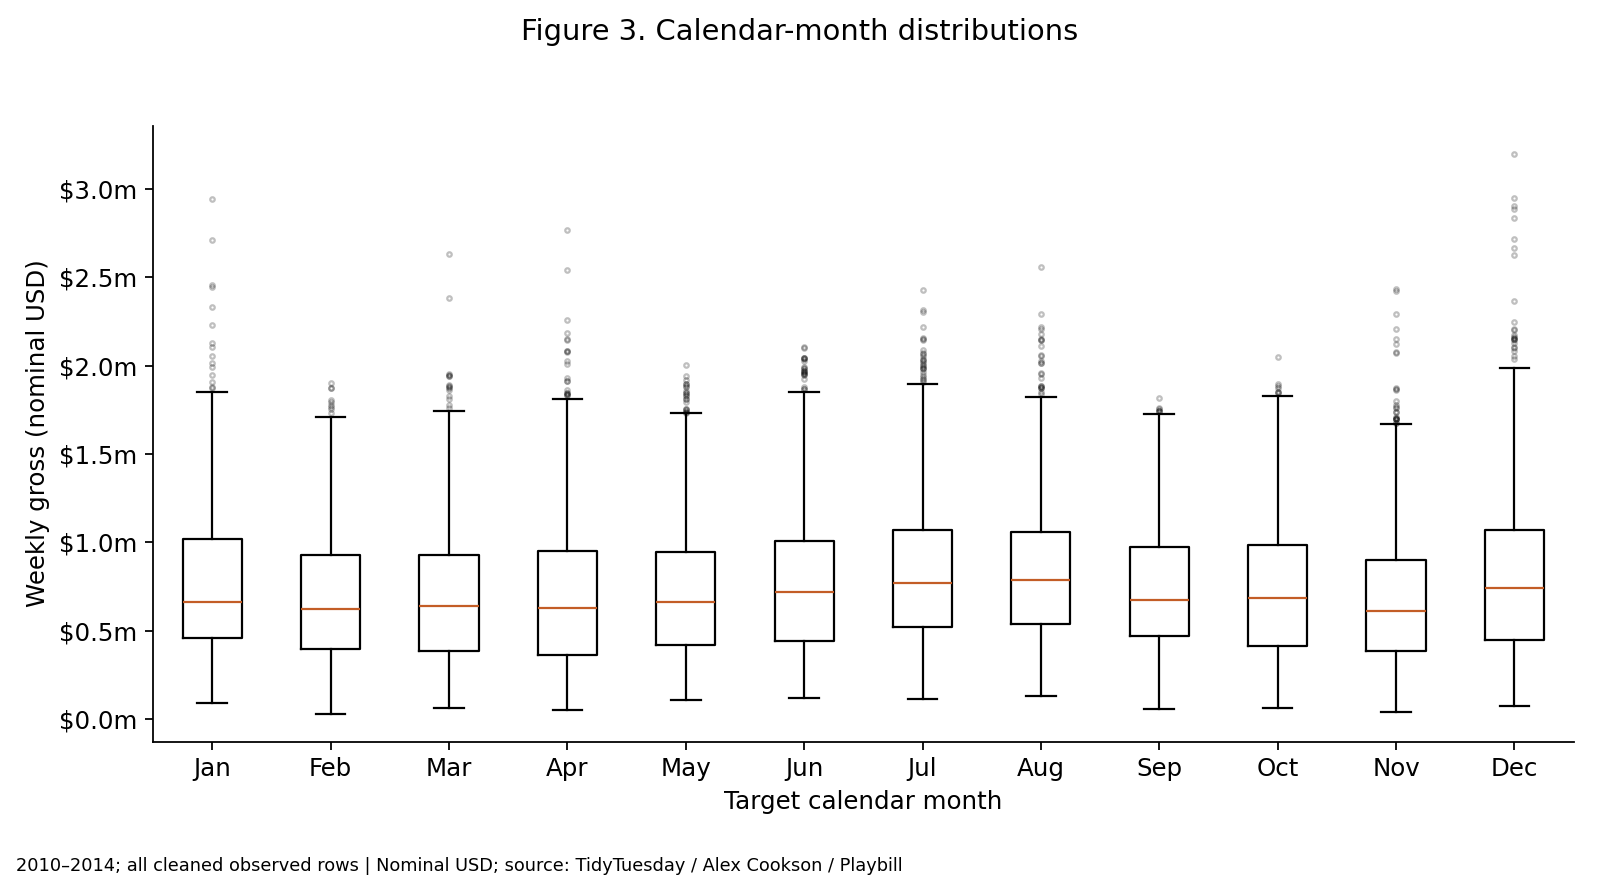

Scope: 2010–2014; all cleaned observed rows


In [5]:
figure = figure_index.loc[figure_index.figure == 3].iloc[0]
display(Image(filename=str(FIGURES / figure.file)))
print("Scope:", figure.scope)

### Figure 4 — Missingness over time

A missing share of 1 means every observed value is absent in that year. Discuss time-dependent missingness before proposing these fields as inputs.


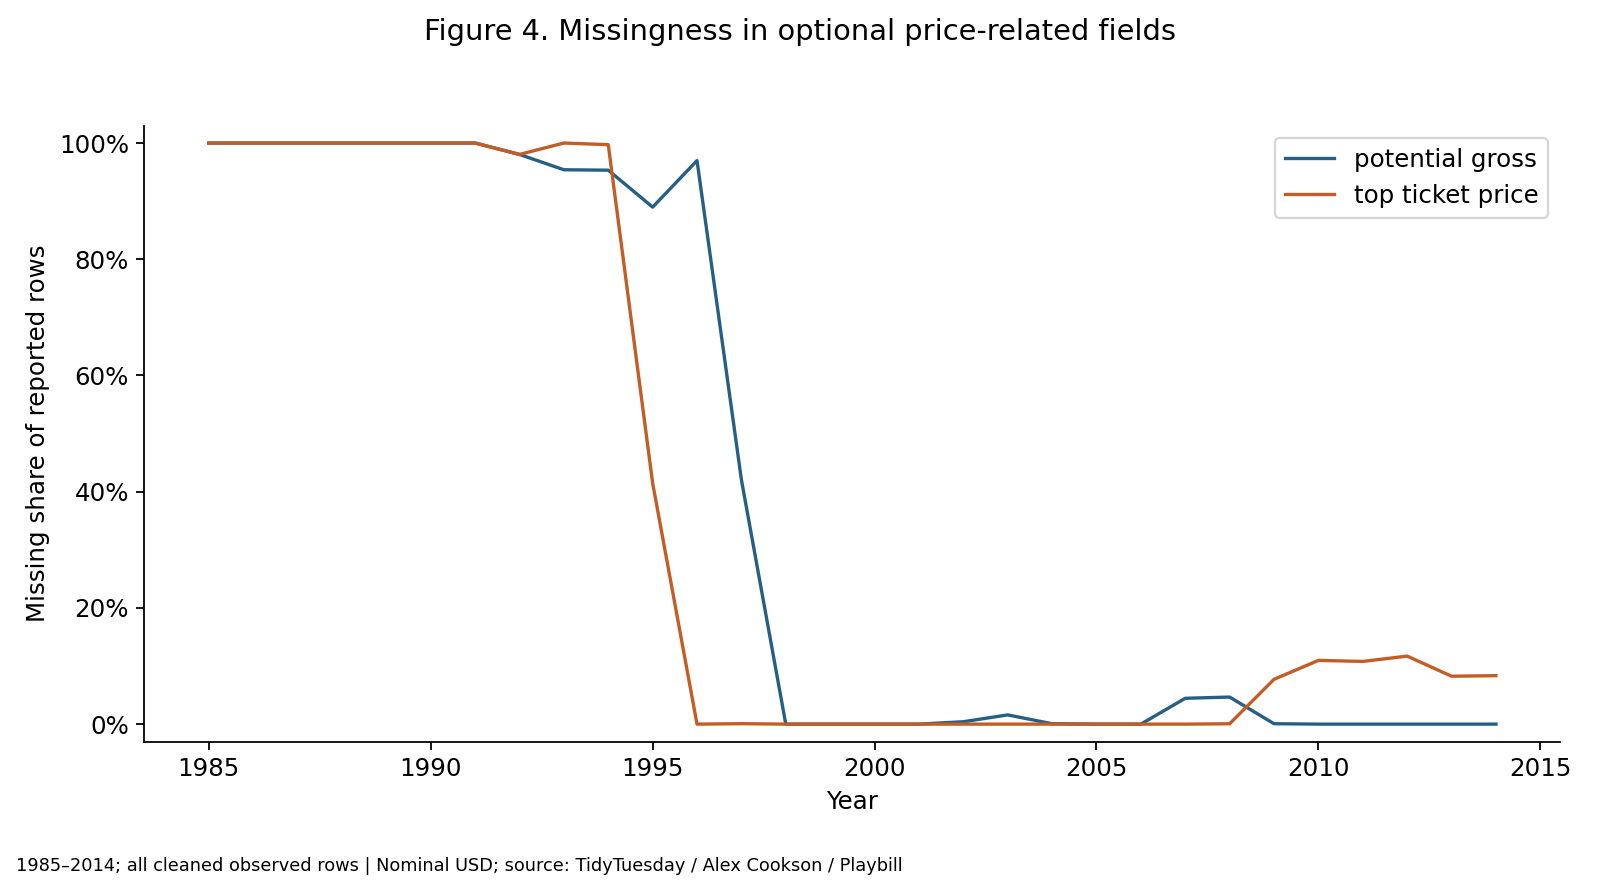

Scope: 1985–2014; all cleaned observed rows


In [6]:
figure = figure_index.loc[figure_index.figure == 4].iloc[0]
display(Image(filename=str(FIGURES / figure.file)))
print("Scope:", figure.scope)

### Figure 5 — Lag relationship

The diagonal means equal previous/target gross. Hexagons aggregate observations on a logarithmic colour scale. Correlation does not guarantee useful ML improvement.


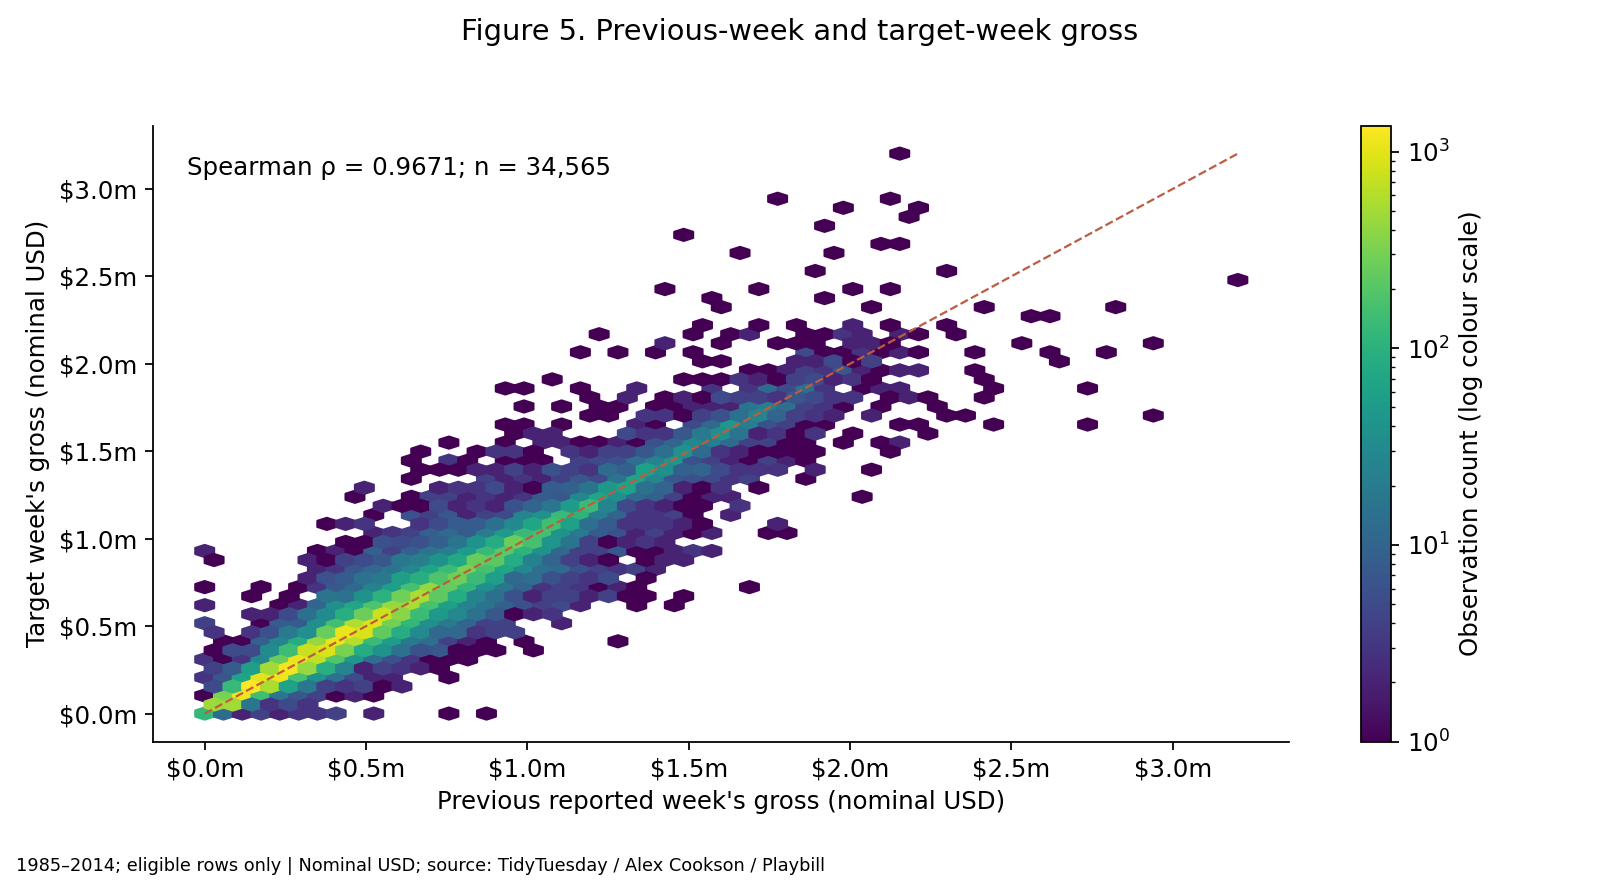

Scope: 1985–2014; eligible rows only


In [7]:
figure = figure_index.loc[figure_index.figure == 5].iloc[0]
display(Image(filename=str(FIGURES / figure.file)))
print("Scope:", figure.scope)

### Figure 6 — Occupancy and revenue

The 100% line locates over-capacity cases. Current occupancy is descriptive here; the forecast uses only previous-week occupancy. Price and venue scale are not isolated by this plot.

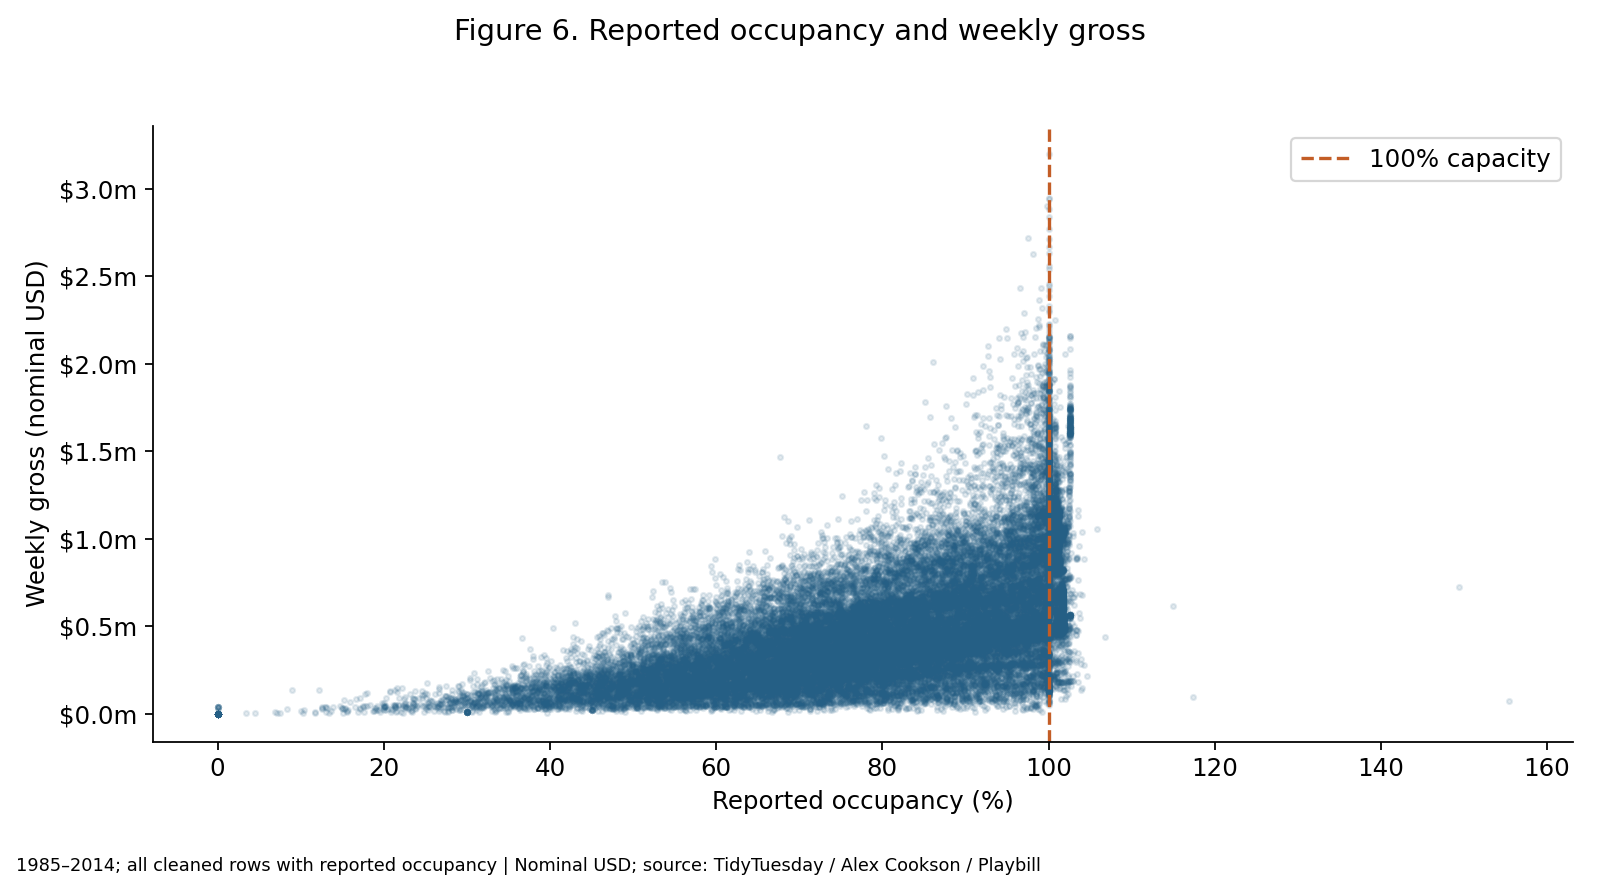

Scope: 1985–2014; all cleaned rows with reported occupancy


In [8]:
figure = figure_index.loc[figure_index.figure == 6].iloc[0]
display(Image(filename=str(FIGURES / figure.file)))
print("Scope:", figure.scope)

### Relationships, outliers and representation

Spearman correlation describes ranks. A floating-point p-value of 0.0 is not literal
zero probability; repeated rows within runs undermine a simple independence assumption.
Run lengths are truncated at the EDA boundary.

In [9]:
display(read_json(TABLES / "lag_relationship.json"))
for filename in ["coverage_year_through_2014.csv", "coverage_run_length_through_2014.csv",
                 "coverage_theatre_through_2014.csv"]:
    display(Markdown(f"**{filename}**"))
    display(pd.read_csv(TABLES / filename))
display(Markdown("**Ten most represented shows (counts, not importance)**"))
display(pd.read_csv(TABLES / "coverage_show_through_2014.csv").head(10))
display(Markdown("**Five largest development grosses for case review**"))
display(pd.read_csv(TABLES / "outlier_review_through_2014.csv").head(5))

{'scope': 'eligible target weeks through 2014',
 'n': 34565,
 'spearman_rho': 0.9671006776378112,
 'p_value': 0.0,
 'caution': 'Repeated observations within runs; p-value is descriptive, not an independence-adjusted test.'}

**coverage_year_through_2014.csv**

,year,rows,eligible_rows,ineligible_rows,eligibility_rate
0,1985,537,405,132,0.7542
1,1986,1051,909,142,0.8649
2,1987,1090,951,139,0.8725
3,1988,1129,1004,125,0.8893
4,1989,1027,881,146,0.8578
5,1990,976,867,109,0.8883
6,1991,863,757,106,0.8772
7,1992,1070,918,152,0.8579
8,1993,935,794,141,0.8492
9,1994,1070,951,119,0.8888


**coverage_run_length_through_2014.csv**

,observed_run_length_band,rows,eligible_rows,ineligible_rows,eligibility_rate
0,1–4,330,0,330,0.0000
1,5–12,3563,1987,1576,0.5577
2,13–52,11182,9226,1956,0.8251
3,53+,23992,23352,640,0.9733


**coverage_theatre_through_2014.csv**

,theatre,rows,eligible_rows,ineligible_rows,eligibility_rate
0,46th Street Theatre,205,181,24,0.8829
1,Al Hirschfeld Theatre,477,433,44,0.9078
2,Ambassador Theatre,1335,1267,68,0.9491
3,American Airlines Theatre,576,405,171,0.7031
4,August Wilson Theatre,482,478,4,0.9917
5,Belasco Theatre,449,319,130,0.7105
6,Bernard B. Jacobs Theatre,407,351,56,0.8624
7,Biltmore Theatre,190,119,71,0.6263
8,Booth Theatre,1129,938,191,0.8308
9,Broadhurst Theatre,1611,1458,153,0.9050


**Ten most represented shows (counts, not importance)**

,show,rows,eligible_rows,ineligible_rows,eligibility_rate
0,The Phantom of the Opera,1408,1404,4,0.9972
1,Les Miserables,953,937,16,0.9832
2,Chicago,949,945,4,0.9958
3,The Lion King,897,889,8,0.9911
4,Cats,797,793,4,0.9950
5,Mamma Mia!,690,682,8,0.9884
6,Beauty and the Beast,690,682,8,0.9884
7,Rent,647,643,4,0.9938
8,Wicked,586,582,4,0.9932
9,Miss Saigon,515,511,4,0.9922


**Five largest development grosses for case review**

,week_ending,show,theatre,weekly_gross,pct_capacity,eligible
0,2013-12-29,Wicked,Gershwin Theatre,3201333.0,1.0000,True
1,2012-12-30,Wicked,Gershwin Theatre,2947172.0,1.0000,True
2,2012-01-01,Spider-Man Turn Off the Dark,Foxwoods Theatre,2941794.0,1.0003,True
3,2014-12-28,Wicked,Gershwin Theatre,2903309.0,0.9985,True
4,2014-12-28,The Lion King,Minskoff Theatre,2885371.0,1.0004,True


## Task 4.1 - Models, preprocessing and tuning

Naive repeats prior gross. Ridge is a regularised linear comparison; correlated lag
inputs make regularisation relevant. Scaling prevents numeric units from setting the
penalty's relative effect. Histogram gradient boosting captures nonlinear thresholds
and interactions but is more complex. Evaluate these trade-offs independently.


In [10]:
from broadway.modelling import build_pipeline, chronological_fold, metric_values
display(Code(inspect.getsource(build_pipeline), language="python"))
display(pd.DataFrame([{"model": model, **params} for model, options in GRID.items() for params in options]))
display(frozen["chosen_parameters"])

def build_pipeline(model_name, params):
    numeric_steps = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if model_name == "ridge":
        numeric_steps.append(("scale", StandardScaler()))
    transform = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ], remainder="drop", sparse_threshold=0)
    if model_name == "ridge":
        estimator = Ridge(**params)
    elif model_name == "hist_gradient_boosting":
        estimator = HistGradientBoostingRegressor(**params, max_iter=150, loss="absolute_error",
                                                  early_stopping=False, random_state=42)
    else:
        raise ValueError(model_name)
    return Pipeline([("transform", transform), ("model", estimator)])

,model,alpha,learning_rate,max_leaf_nodes
0,ridge,1.0,NaN,NaN
1,ridge,10.0,NaN,NaN
2,ridge,100.0,NaN,NaN
3,hist_gradient_boosting,NaN,0.05,15.0
4,hist_gradient_boosting,NaN,0.05,31.0
5,hist_gradient_boosting,NaN,0.10,15.0
6,hist_gradient_boosting,NaN,0.10,31.0


{'ridge': {'alpha': 10.0},
 'hist_gradient_boosting': {'learning_rate': 0.1, 'max_leaf_nodes': 31}}

## Task 4.2 - Chronological splits and metrics

Train through 2014/2015/2016; validate on 2015/2016/2017. Complete weeks stay together.
Random shuffling would mix past and future. Observed eligible dates need not fill
every calendar week. Selected settings are refitted on all eligible pre-2018 rows.
The same folds tune and describe models, so these are development scores, not unbiased
final-test estimates.


In [11]:
display(Code(inspect.getsource(chronological_fold), language="python"))
display(Code(inspect.getsource(metric_values), language="python"))
display(pd.read_csv(TABLES / "validation_fold_boundaries.csv"))
display(pd.read_csv(TABLES / "validation_tuning.csv"))

def chronological_fold(frame, train_end, validation_year):
    train = frame.loc[frame.week_ending < pd.Timestamp(f"{train_end + 1}-01-01")]
    valid = frame.loc[(frame.week_ending >= pd.Timestamp(f"{validation_year}-01-01"))
                      & (frame.week_ending < pd.Timestamp(f"{validation_year + 1}-01-01"))]
    if train.empty or valid.empty:
        raise ValueError(f"Empty chronological fold {train_end}/{validation_year}")
    if train.week_ending.max() >= valid.week_ending.min():
        raise ValueError("Chronological train/validation overlap")
    assert set(train.week_ending).isdisjoint(set(valid.week_ending))
    return train, valid

def metric_values(actual, prediction):
    return {"mae_usd": float(mean_absolute_error(actual, prediction)),
            "rmse_usd": float(np.sqrt(mean_squared_error(actual, prediction))),
            "mean_signed_error_usd": float(np.mean(np.asarray(prediction) - np.asarray(actual)))}

,train_through_year,validation_year,train_first,train_last,validation_first,validation_last,train_rows,validation_rows,train_weeks,validation_weeks
0,2014,2015,1985-07-07,2014-12-28,2015-01-04,2015-12-20,34565,1389,1539,51
1,2015,2016,1985-07-07,2015-12-20,2016-01-31,2016-12-25,35954,1356,1590,48
2,2016,2017,1985-07-07,2016-12-25,2017-01-01,2017-12-31,37310,1444,1638,53


,model,parameters,validation_year,rows,mae_usd,rmse_usd,mean_signed_error_usd,mae_reduction_vs_naive_pct
0,naive,{},2015,1389,88830.9777,138118.8917,4133.2642,0.0000
1,ridge,"{""alpha"": 1.0}",2015,1389,87477.2009,131282.3534,3297.6703,1.5240
2,ridge,"{""alpha"": 10.0}",2015,1389,87273.6982,131152.9186,2542.0571,1.7531
3,ridge,"{""alpha"": 100.0}",2015,1389,87301.0731,131263.2133,785.8909,1.7223
4,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15}",2015,1389,84575.9634,131551.8916,-9626.9783,4.7900
5,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31}",2015,1389,83926.2634,131103.2891,-8214.4373,5.5214
6,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15}",2015,1389,84128.5538,129585.5442,-6845.7163,5.2937
7,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31}",2015,1389,83831.8001,131128.9653,-7503.9509,5.6277
8,naive,{},2016,1356,88103.7206,138278.6986,-10868.2540,0.0000
9,ridge,"{""alpha"": 1.0}",2016,1356,81907.4134,126286.9066,-9812.1782,7.0330


## Task 4.3 - Selected comparison and independent arithmetic

Select frozen settings, recompute each year's MAE from saved predictions, then average
folds equally. This does not fit models or generate predictions. Distinguish the
lowest-error candidate from the method retained by the 5% rule.

In [12]:
summary = pd.read_csv(TABLES / "validation_summary.csv")
selected = summary.loc[summary.apply(lambda r: json.loads(r.parameters) ==
    frozen["chosen_parameters"].get(r.model, {}), axis=1)].copy()
display(selected)
predictions = pd.read_csv(TABLES / "validation_predictions.csv")
errors = (predictions.prediction_usd - predictions.weekly_gross).abs()
recomputed = predictions.assign(recomputed_absolute_error=errors).groupby(
    ["model", "validation_year"]).recomputed_absolute_error.mean().unstack()
recomputed["equal_fold_mean_mae"] = recomputed.mean(axis=1)
display(recomputed)
for row in selected.itertuples():
    assert np.isclose(row.mean_validation_mae_usd, recomputed.loc[row.model, "equal_fold_mean_mae"])
print("Saved MAEs agree with independent arithmetic.")
print("Method retained by the frozen 5% rule:", frozen["validation_selected_method"])

,model,parameters,mean_validation_mae_usd,mean_validation_rmse_usd,mean_validation_signed_error_usd,folds,mae_reduction_vs_naive_pct
0,ridge,"{""alpha"": 10.0}",94857.2544,156111.4151,-10683.1154,3,3.8140
3,naive,{},98618.5513,167774.9419,-8519.0649,3,0.0000
4,hist_gradient_boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31}",100827.9817,177578.2134,-32913.8677,3,-2.2404


validation_year,2015,2016,2017,equal_fold_mean_mae
model,,,,
hist_gradient_boosting,83831.8001,84360.6119,134291.5332,100827.9817
naive,88830.9777,88103.7206,118920.9557,98618.5513
ridge,87273.6982,81926.5634,115371.5015,94857.2544


Saved MAEs agree with independent arithmetic.
Method retained by the frozen 5% rule: naive


## Task 4.4 - Subgroup evidence and limits

Pooled errors by known run age and theatre describe variations within the evaluated
population. A group under 30 rows is flagged for inspection, not certified unreliable
or reliable. No dependence-adjusted confidence intervals or causal explanations are supplied.


In [13]:
display(pd.read_csv(TABLES / "validation_subgroups_known_run_age_band.csv"))
display(pd.read_csv(TABLES / "validation_subgroups_theatre.csv"))

,subgroup,model,rows,weeks,small_subgroup_under_30,mae_usd,rmse_usd,mean_signed_error_usd,mae_reduction_vs_naive_pct
0,4–12 earlier weeks,hist_gradient_boosting,1094,152,False,73273.0668,127630.5837,-18211.1052,7.5392
1,4–12 earlier weeks,naive,1094,152,False,79247.7359,128959.0899,-25271.4819,0.0000
2,4–12 earlier weeks,ridge,1094,152,False,76998.1141,124561.0163,-24452.8456,2.8387
3,13–52,hist_gradient_boosting,1782,143,False,94733.7176,177272.5030,-25181.0269,0.0880
4,13–52,naive,1782,143,False,94817.1289,177353.4609,-6360.8150,0.0000
5,13–52,ridge,1782,143,False,91638.0224,166219.6919,-8748.6134,3.3529
6,53–260,hist_gradient_boosting,1058,103,False,137364.8156,252701.3832,-64390.7997,-15.6061
7,53–260,naive,1058,103,False,118821.4616,200132.3906,-624.3675,0.0000
8,53–260,ridge,1058,103,False,112431.4212,180619.9045,-6237.8082,5.3779
9,261+,hist_gradient_boosting,255,51,False,119388.7810,183075.9555,-28383.9474,8.3076


,subgroup,model,rows,weeks,small_subgroup_under_30,mae_usd,rmse_usd,mean_signed_error_usd,mae_reduction_vs_naive_pct
0,Al Hirschfeld Theatre,hist_gradient_boosting,152,152,False,95913.0869,147744.1341,-9188.0910,9.3312
1,Al Hirschfeld Theatre,naive,152,152,False,105783.9628,168700.6838,-2377.4215,0.0000
2,Al Hirschfeld Theatre,ridge,152,152,False,100154.3075,153774.6173,103.6256,5.3218
3,Ambassador Theatre,hist_gradient_boosting,152,152,False,64853.0739,108550.5938,-12313.7399,15.4138
4,Ambassador Theatre,naive,152,152,False,76670.9695,126812.7727,-4151.3413,0.0000
...,...,...,...,...,...,...,...,...,...
118,Walter Kerr Theatre,naive,89,89,False,50251.5056,70551.8806,5241.3843,0.0000
119,Walter Kerr Theatre,ridge,89,89,False,49311.9233,65845.7959,7452.6618,1.8698
120,Winter Garden Theatre,hist_gradient_boosting,115,115,False,133784.9586,208914.4410,-26051.0936,11.5345
121,Winter Garden Theatre,naive,115,115,False,151228.4553,235199.6733,-12681.4278,0.0000


## Task 4.5 - Reserved final evaluation and saved results

The period is 1 January 2018–1 March 2020. Earlier reported outcomes supply later lags,
but no holdout rows fit models. Review fixed predictors, parameters, KPI and timing
assumptions before deliberate unlocking. 

In [14]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    from broadway.modelling import run_final
    display(run_final(unlocked=True))
else:
    receipt_path = TABLES / "final_evaluation_receipt.json"
    if receipt_path.exists():
        receipt = read_json(receipt_path)
        display(receipt)
        if receipt["status"] != "completed":
            raise RuntimeError("Inspect the incomplete final evaluation; do not rerun it.")
        display(pd.read_csv(TABLES / "final_metrics.csv"))
        display(pd.read_csv(TABLES / "final_subgroups_known_run_age_band.csv"))
        display(pd.read_csv(TABLES / "final_subgroups_theatre.csv"))
        display(read_json(AUDIT / "final_verification.json"))
        print("Saved final results only; no new scoring. Frozen selected method:",
              frozen["validation_selected_method"])
    else:
        print("Final holdout locked; no final scores exist.")

{'status': 'completed',
 'at_utc': '2026-11-20T03:10:22.300901+00:00',
 'rows_per_model': 3285,
 'frozen_protocol_sha256': 'a9849da199fb7493c21ca2bd86f74e99bc095dd184a9cc18f15f03a5641e330d',
 'kpi_reduction_pct_recorded_before_evaluation': 5.0,
 'validation_selected_method': 'naive'}

,model,rows,weeks,mae_usd,rmse_usd,mean_signed_error_usd,mae_reduction_vs_naive_pct,meets_example_kpi
0,hist_gradient_boosting,3285,113,100291.8139,168938.8833,-20970.8692,8.6641,True
1,naive,3285,113,109805.4337,191796.2816,3431.3954,0.0000,False
2,ridge,3285,113,103087.4665,171631.3570,1120.1544,6.1181,True


,subgroup,model,rows,weeks,small_subgroup_under_30,mae_usd,rmse_usd,mean_signed_error_usd,mae_reduction_vs_naive_pct
0,4–12 earlier weeks,hist_gradient_boosting,650,112,False,74590.8706,141003.5963,-15684.5668,8.4613
1,4–12 earlier weeks,naive,650,112,False,81485.6523,153217.3007,-11965.4144,0.0000
2,4–12 earlier weeks,ridge,650,112,False,79044.0158,143203.6757,-15861.3403,2.9964
3,13–52,hist_gradient_boosting,931,113,False,87720.2606,144415.2859,-5948.8760,8.3304
4,13–52,naive,931,113,False,95691.7419,166486.2206,5357.6660,0.0000
5,13–52,ridge,931,113,False,89254.4206,146789.8007,5861.2795,6.7271
6,53–260,hist_gradient_boosting,1704,113,False,116964.1902,189846.4322,-31194.7967,8.8491
7,53–260,naive,1704,113,False,128319.3451,216373.7001,8252.1516,0.0000
8,53–260,ridge,1704,113,False,119816.8143,192855.1829,5007.4691,6.6261


,subgroup,model,rows,weeks,small_subgroup_under_30,mae_usd,rmse_usd,mean_signed_error_usd,mae_reduction_vs_naive_pct
0,Al Hirschfeld Theatre,hist_gradient_boosting,98,98,False,115279.0425,166908.3570,-28383.0599,3.7591
1,Al Hirschfeld Theatre,naive,98,98,False,119781.7474,194239.9656,6847.8852,0.0000
2,Al Hirschfeld Theatre,ridge,98,98,False,113955.1377,163938.7831,2252.7592,4.8644
3,Ambassador Theatre,hist_gradient_boosting,113,113,False,61000.0265,95644.2116,-12543.0883,19.4846
4,Ambassador Theatre,naive,113,113,False,75761.9055,126944.5116,6313.3301,0.0000
...,...,...,...,...,...,...,...,...,...
118,Walter Kerr Theatre,naive,60,60,False,173401.3938,247530.1213,10331.7092,0.0000
119,Walter Kerr Theatre,ridge,60,60,False,157577.9021,207559.4154,10521.0331,9.1254
120,Winter Garden Theatre,hist_gradient_boosting,100,100,False,124822.3776,196035.8439,-26825.7306,18.0122
121,Winter Garden Theatre,naive,100,100,False,152245.0892,247588.8644,6894.2176,0.0000


{'verified_at_utc': '2026-11-22T14:49:34.866745+00:00',
 'snapshot_checks_passed': 13,
 'raw_rows': 47524,
 'eligible_rows': 42039,
 'figures_verified': 6,
 'tuning_rows': 24,
 'chronological_folds': 3,
 'validation_predictions_per_model': 4189,
 'selected_predictions_match_tuning_scores': True,
 'subgroup_counts_and_scores_verified': True,
 'frozen_hashes_match': True,
 'raw_bytes_match_manifest': True,
 'validation_keys_actuals_match_source': True,
 'summary_grid_selection_and_fold_counts_verified': True,
 'real_final_holdout_locked': False,
 'real_final_holdout_evaluated': True,
 'final_predictions_per_model': 3285,
 'final_weeks': 113,
 'final_keys_actuals_metrics_and_subgroups_match': True}

Saved final results only; no new scoring. Frozen selected method: naive


### Reading the final comparison

Both learned candidates exceed the example 5% MAE-reduction target on the saved final
sample. Boosting has the lowest final MAE/RMSE; Ridge's signed error is closer to zero.
The development-selected method remains naive. Do not use this final ranking to
claim an independently tested new selection rule. Examine absolute errors, directional
bias and subgroups together; signed errors can cancel. Any new model choice needs
future unseen evidence, and forecast improvement does not measure business benefit.